# Facial Expression Classification (FER)

This notebook adapts the supplied introductory CNN notebook to the uploaded FER dataset. It maps alternate emotion folder names into seven canonical classes and evaluates on the provided test split.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Locate the project folder automatically.
# Expected layout:
# FER_EXPRESSION_PROJECT/
#   FER_56_per_class/train, FER_56_per_class/test
#   train_model.py
#   FER_image_classification.ipynb

PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "FER_56_per_class").is_dir()
           and (PROJECT_ROOT / "train_model.py").is_file()):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Could not locate project root. Open this notebook from the "
            "FER_EXPRESSION_PROJECT folder containing FER_56_per_class and train_model.py."
        )
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from train_model import (
    CLASS_NAMES, IMAGE_SIZE, BATCH_SIZE,
    collect_images, make_dataset, build_model
)

DATA_ROOT = PROJECT_ROOT / "FER_56_per_class"
OUTPUT_DIR = PROJECT_ROOT

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATA_ROOT)
print("Train folder exists:", (DATA_ROOT / "train").is_dir())
print("Test folder exists:", (DATA_ROOT / "test").is_dir())


Project root: C:\FER_facial_expression_project\fer_expression_project
Dataset root: C:\FER_facial_expression_project\fer_expression_project\FER_56_per_class
Train folder exists: True
Test folder exists: True


## 1. Load image paths and labels

The dataset has a `train/` and `test/` split. Alternate spellings such as `fear` and `fearful` are treated as one class.

In [2]:
# Load the train/ and test/ folders directly from FER_56_per_class.
train_paths, train_labels = collect_images(DATA_ROOT / "train")
test_paths, test_labels = collect_images(DATA_ROOT / "test")

print("Training images:", len(train_paths))
print("Testing images:", len(test_paths))

for i, name in enumerate(CLASS_NAMES):
    print(
        f"{name}: train={(train_labels == i).sum()}, "
        f"test={(test_labels == i).sum()}"
    )


Training images: 392
Testing images: 7178
angry: train=56, test=958
disgusted: train=56, test=111
fearful: train=56, test=1024
happy: train=56, test=1774
neutral: train=56, test=1233
sad: train=56, test=1247
surprised: train=56, test=831


## 2. Create training and validation datasets

In [3]:
# Create a stratified 80/20 train-validation split from the training folder.
tr_p, val_p, tr_y, val_y = train_test_split(
    train_paths,
    train_labels,
    test_size=0.20,
    random_state=42,
    stratify=train_labels
)

# Build TensorFlow datasets.
train_ds = make_dataset(tr_p, tr_y, training=True)
val_ds = make_dataset(val_p, val_y)
test_ds = make_dataset(test_paths, test_labels)

print("Training samples:", len(tr_y))
print("Validation samples:", len(val_y))
print("Test samples:", len(test_labels))


Training samples: 313
Validation samples: 79
Test samples: 7178


## 3. Build and train the CNN

In [ ]:
# Calculate balanced class weights using the training split labels.
classes = np.unique(tr_y)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=tr_y
)
class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}
print("Class weights:", class_weights)

# Build the CNN.
model = build_model()
model.summary()

# Save the best checkpoint in the project folder.
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        str(OUTPUT_DIR / "facial_expression_model.keras"),
        monitor="val_loss", save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weights,
   
)

model.save(OUTPUT_DIR / "facial_expression_model.keras")
print("Training completed. Model saved to:", OUTPUT_DIR / "facial_expression_model.keras")


Class weights: {0: 0.9936507936507937, 1: 0.9936507936507937, 2: 0.9936507936507937, 3: 1.0162337662337662, 4: 0.9936507936507937, 5: 0.9936507936507937, 6: 1.0162337662337662}


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,047 (433.78 KB)

 Trainable params: 110,855 (433.03 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.1329 - loss: 2.3560 - val_accuracy: 0.1519 - val_loss: 1.9459
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.1547 - loss: 2.0901 - val_accuracy: 0.1519 - val_loss: 1.9432
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.1750 - loss: 2.1431 - val_accuracy: 0.1899 - val_loss: 1.9454
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.1727 - loss: 2.0431 - val_accuracy: 0.1392 - val_loss: 1.9443
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.1711 - loss: 2.0187 - val_accuracy: 0.0759 - val_loss: 1.9455
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.1761 - loss: 1.9338 - val_accuracy: 0.1392 - val_loss: 1.9467
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.1598 - loss: 2.0076 - val_accuracy: 0.1392 - val_loss: 1.9469
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.1903 - loss: 1.9439 - val_accuracy: 0.1392 - v

## 4. Plot training history

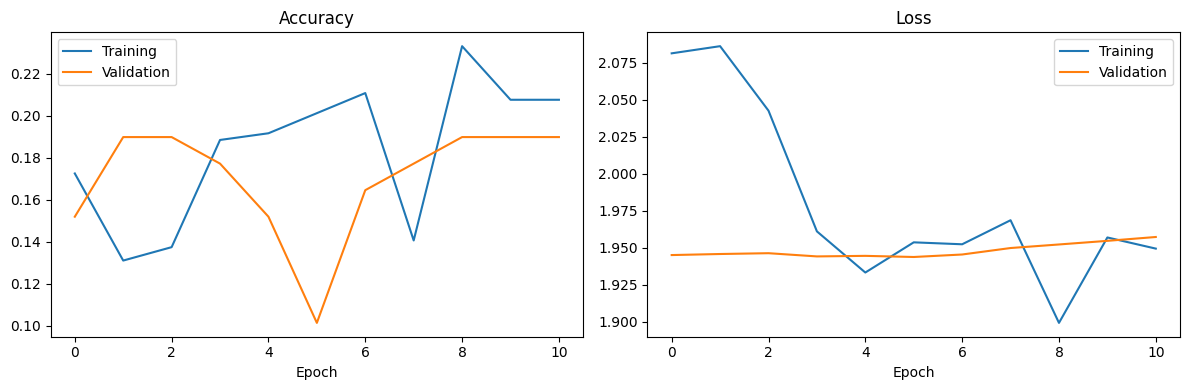

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()


## 5. Evaluate on the held-out test set

225/225 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.2431 - loss: 1.9134
{'accuracy': 0.2003343552350998, 'loss': 1.9456590414047241}
              precision    recall  f1-score   support

       angry       0.13      0.22      0.16       958
   disgusted       0.00      0.00      0.00       111
     fearful       0.09      0.07      0.08      1024
       happy       0.24      0.64      0.35      1774
     neutral       0.00      0.00      0.00      1233
         sad       0.00      0.00      0.00      1247
   surprised       0.41      0.02      0.04       831

    accuracy                           0.20      7178
   macro avg       0.12      0.14      0.09      7178
weighted avg       0.14      0.20      0.12      7178



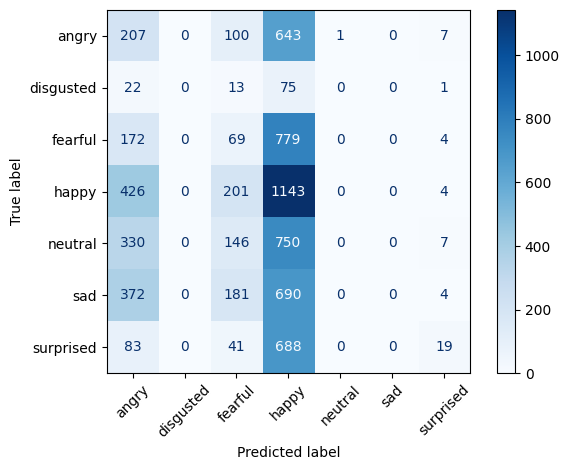

In [ ]:
print(model.evaluate(test_ds, return_dict=True))
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)
print(classification_report(y_true, y_pred, labels=range(len(CLASS_NAMES)), target_names=CLASS_NAMES, zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES)))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(xticks_rotation=45, cmap="Blues")
plt.tight_layout()


## 6. Save model and class names

In [ ]:
# Save the trained model and class-name mapping in the project folder.
model.save(OUTPUT_DIR / "facial_expression_model.keras")
with open(OUTPUT_DIR / "classes.json", "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, indent=2)

print("Saved model and classes.json in:", OUTPUT_DIR)


Saved model and classes.json in: C:\FER_facial_expression_project\fer_expression_project


## 7. Predict one image

In [ ]:
from PIL import Image

image_path = test_paths[0]
image = Image.open(image_path).convert("RGB").resize(IMAGE_SIZE)
x = np.asarray(image, dtype=np.float32)[None, ...]
scores = model.predict(x, verbose=0)[0]

print("Image:", image_path)
print("Predicted:", CLASS_NAMES[int(scores.argmax())])
print(dict(zip(CLASS_NAMES, scores.round(4))))


Image: C:\FER_facial_expression_project\fer_expression_project\FER_56_per_class\test\angry\im0.png
Predicted: happy
{'angry': 0.1361, 'disgusted': 0.147, 'fearful': 0.1472, 'happy': 0.1589, 'neutral': 0.1238, 'sad': 0.1291, 'surprised': 0.158}
